In [57]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [58]:
df=pd.read_csv("graduate_admission_dataset_500.csv")
df.head()
df.drop(columns=['Serial No.'],inplace=True)
df.isnull().sum()
df.duplicated()

0      False
1      False
2      False
3      False
4      False
       ...  
495    False
496    False
497    False
498    False
499    False
Length: 500, dtype: bool

In [73]:
x=df.iloc[:,0:-1]
y=df.iloc[:,-1]
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=45,test_size=0.2)
x_test


,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research
204,299,93,1,1.8,3.0,9.04,1
481,305,108,3,4.0,1.5,7.48,1
296,327,105,3,4.7,4.9,8.25,1
38,300,113,3,3.8,3.3,7.03,1
298,326,105,4,3.5,3.1,8.37,1
...,...,...,...,...,...,...,...
79,292,114,3,2.0,2.8,7.56,1
476,323,101,2,4.0,4.2,8.57,1
69,308,102,1,1.3,1.1,9.04,1
73,335,103,2,3.6,2.9,8.92,0


In [74]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

x_train_scaled
x_test_scaled

array([[0.18      , 0.1       , 0.        , 0.2       , 0.5       ,
        0.72571429, 1.        ],
       [0.3       , 0.6       , 0.5       , 0.75      , 0.125     ,
        0.28      , 1.        ],
       [0.74      , 0.5       , 0.5       , 0.925     , 0.975     ,
        0.5       , 1.        ],
       [0.2       , 0.76666667, 0.5       , 0.7       , 0.575     ,
        0.15142857, 1.        ],
       [0.72      , 0.5       , 0.75      , 0.625     , 0.525     ,
        0.53428571, 1.        ],
       [0.48      , 1.        , 0.75      , 0.575     , 0.225     ,
        0.98285714, 1.        ],
       [0.64      , 0.3       , 0.25      , 0.45      , 0.675     ,
        0.17142857, 1.        ],
       [0.64      , 0.56666667, 0.        , 0.8       , 0.275     ,
        0.20571429, 1.        ],
       [0.82      , 0.93333333, 0.75      , 0.2       , 0.825     ,
        0.32571429, 1.        ],
       [0.72      , 0.83333333, 0.75      , 0.625     , 0.525     ,
        0.16285714, 0. 

In [75]:
import tensorflow
from tensorflow import keras
from keras import Sequential
from keras.layers import Dense




In [76]:
model=Sequential()

model.add(Dense(7,activation='relu',input_dim=7))
model.add(Dense(7,activation='relu'))
model.add(Dense(7,activation='relu'))
model.add(Dense(1,activation='linear'))
model.summary()


c:\Users\prem pratap\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_45 (Dense)                │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_46 (Dense)                │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_47 (Dense)                │ (None, 7)              │            56 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_48 (Dense)                │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 176 (704.00 B)

 Trainable params: 176 (704.00 B)

 Non-trainable params: 0 (0.00 B)

In [80]:
model.compile(loss='mean_squared_error', optimizer='Adam')

history=model.fit(x_train_scaled,y_train,epochs=100,validation_split=0.2)

Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 15ms/step - loss: 0.0089 - val_loss: 0.0077
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0069 - val_loss: 0.0061
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0054 - val_loss: 0.0049
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0044 - val_loss: 0.0042
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.0037 - val_loss: 0.0038
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0033 - val_loss: 0.0034
Epoch 7/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0030 - val_loss: 0.0032
Epoch 8/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0027 - val_loss: 0.0029
Epoch 9/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0026 - val_loss: 0.0028
Epoch 10/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0024 - val_loss: 0.0026
Epoch 11/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 0.0023 - val_loss: 0.0025
Epoch 12/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 

In [81]:
y_pred=model.predict(x_test_scaled)
y_pred

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step


array([[0.46575767],
       [0.51954645],
       [0.7168802 ],
       [0.5343587 ],
       [0.6921081 ],
       [0.7635344 ],
       [0.52715665],
       [0.55883133],
       [0.74019265],
       [0.66167235],
       [0.67886513],
       [0.6654696 ],
       [0.64339775],
       [0.62566155],
       [0.5747685 ],
       [0.52368844],
       [0.70923305],
       [0.7632687 ],
       [0.6527124 ],
       [0.61485326],
       [0.488233  ],
       [0.6958436 ],
       [0.46213606],
       [0.6992503 ],
       [0.5613156 ],
       [0.538882  ],
       [0.3972993 ],
       [0.62265676],
       [0.5457303 ],
       [0.71434164],
       [0.60179466],
       [0.54147655],
       [0.57962066],
       [0.596598  ],
       [0.49626985],
       [0.5670311 ],
       [0.55745566],
       [0.72051275],
       [0.5751209 ],
       [0.7759082 ],
       [0.63051057],
       [0.5776538 ],
       [0.636421  ],
       [0.5431654 ],
       [0.5285035 ],
       [0.5709248 ],
       [0.44999266],
       [0.618

In [82]:
from sklearn.metrics import r2_score
r2_score(y_test, y_pred)

0.8418308713221909

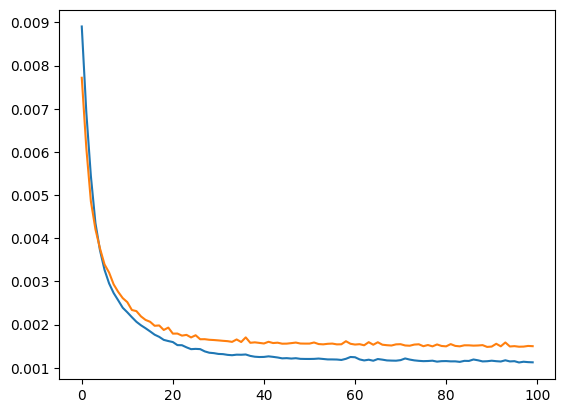

In [85]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])